# 02. Las piezas de una serie

Teórica de series temporales, Analítica de Datos (UdeSA). Este cuaderno acompaña el bloque 2 de la clase.

Una serie se puede pensar como la suma (o el producto) de piezas:

- **Tendencia** ($T_t$): el nivel de fondo, que cambia en meses o años.
- **Ciclos** o estacionalidad ($S_t$): patrones que se repiten con un período fijo. El subte tiene tres: el día, la semana y el año.
- **Residuo** ($R_t$): lo que queda después de sacar lo anterior.

En una descomposición aditiva, $y_t = T_t + S_t + R_t$: los ciclos suman una cantidad fija de pasajeros. En una multiplicativa, $y_t = T_t \times S_t \times R_t$: los ciclos son un porcentaje del nivel. Tomando logaritmos, la multiplicativa se vuelve aditiva: $\log y_t = \log T_t + \log S_t + \log R_t$.

Contenido:

1. Los tres ciclos del subte.
2. Aditiva o multiplicativa.
3. `seasonal_decompose`, con un solo período.
4. `MSTL`, con los períodos de 7 y 365 días.
5. Los residuos y los feriados.
6. Otra forma de estacionalidad: subte contra Ecobici.

In [1]:
import sys

# Dirección de los datos cuando el notebook corre en Colab.
# Si los datos se suben a otro lado, hay que cambiar esta constante.
URL_DATOS_COLAB = "https://raw.githubusercontent.com/ferkrodriguez98/teorica-series-temporales/main/datos_clase/"

EN_COLAB = "google.colab" in sys.modules
BASE = URL_DATOS_COLAB if EN_COLAB else "../datos_clase/"
print("Datos:", BASE)

Datos: ../datos_clase/


In [2]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from matplotlib.ticker import FuncFormatter

# Colores: tinta para lo observado, rojo para pronósticos y resaltados
TINTA, GRIS, ROJO = "#1f2430", "#9aa0a6", "#c62828"
LINEAS = {"A": "#1a9fd0", "B": "#d7182a", "C": "#1d4f9c", "D": "#008a57", "E": "#6c2c87", "H": "#e0a800"}
ECOBICI = "#d4a017"

warnings.simplefilter("ignore", FutureWarning)   # avisos de cambios en versiones futuras de las librerías

plt.rcParams.update({
    "figure.figsize": (10, 3.6), "figure.dpi": 100, "savefig.bbox": "tight",
    "axes.grid": True, "grid.color": "#e6e6e6", "grid.linewidth": 0.6,
    "axes.spines.top": False, "axes.spines.right": False, "axes.edgecolor": "#b0b0b0",
    "axes.titlesize": 11.5, "axes.titlelocation": "left", "axes.labelsize": 10,
    "axes.labelcolor": "#444444", "xtick.color": "#555555", "ytick.color": "#555555",
    "legend.frameon": False, "legend.fontsize": 9.5, "lines.linewidth": 1.1,
})

def num(x, dec=0):
    # Número con punto de miles y coma decimal
    return f"{x:,.{dec}f}".replace(",", "X").replace(".", ",").replace("X", ".")

def pct(x, dec=0):
    return num(100 * x, dec) + " %"

en_millones = FuncFormatter(lambda v, _: num(v / 1e6, 1))
en_miles = FuncFormatter(lambda v, _: num(v / 1e3))

from statsmodels.tsa.seasonal import seasonal_decompose, MSTL

DIAS = ["lunes", "martes", "miércoles", "jueves", "viernes", "sábado", "domingo"]
MESES = ["ene", "feb", "mar", "abr", "may", "jun", "jul", "ago", "sep", "oct", "nov", "dic"]

In [3]:
total = pd.read_csv(BASE + "subte_diario_total.csv", parse_dates=["fecha"], index_col="fecha")["pax"]

feriados = pd.read_csv(BASE + "feriados.csv", parse_dates=["fecha"])
feriados = feriados[(feriados["ambito"] == "nacional") | feriados["ambito"].str.startswith("CABA")]
no_habiles = set(feriados["fecha"])
es_feriado = total.index.isin(feriados["fecha"])

eventos = pd.read_csv(BASE + "eventos_verificados.csv", parse_dates=["fecha"]).set_index("fecha")
print(len(total), "días;", int(es_feriado.sum()), "feriados o días no laborables en el período")

4840 días; 254 feriados o días no laborables en el período


## 1. Los tres ciclos del subte

- **Día**: perfil promedio cada 15 minutos de los días hábiles de 2025.
- **Semana**: promedio por día de la semana en 2025, sin feriados.
- **Año**: promedio de cada mes dividido el promedio de su año, para los años completos sin pandemia (2014 a 2019 y 2022 a 2025).

Enero: 71 % del promedio de su año; julio: 105 %


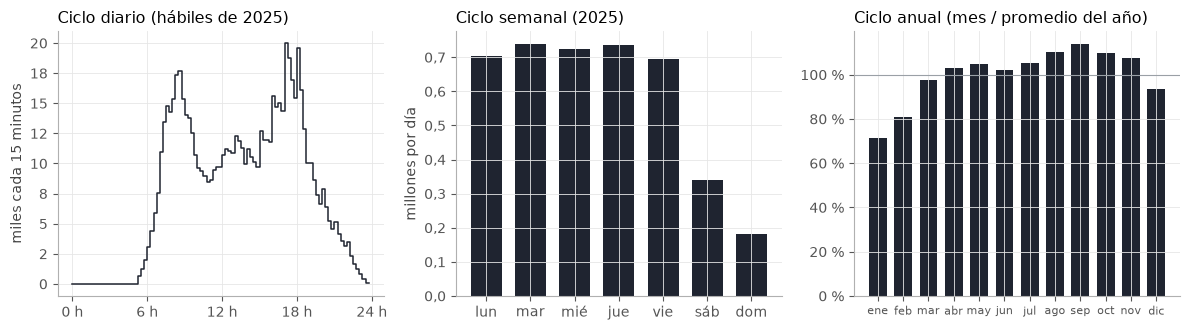

In [4]:
q = pd.read_csv(BASE + "subte_15min_linea.csv.gz")
q = q[q["fecha"].str.startswith("2025")]
q["fecha"] = pd.to_datetime(q["fecha"])
habiles = q[(q["fecha"].dt.day_of_week < 5) & ~q["fecha"].isin(no_habiles)]
perfil = habiles.groupby("desde")["pax"].sum() / habiles["fecha"].nunique()
perfil.index = [int(h[:2]) + int(h[3:]) / 60 for h in perfil.index]

s25 = total.loc["2025"]
semana = s25[~s25.index.isin(no_habiles)].groupby(lambda d: d.day_of_week).mean()

anios = list(range(2014, 2020)) + list(range(2022, 2026))
mensual = total.resample("MS").mean()
relativo = pd.concat([mensual.loc[str(a)] / mensual.loc[str(a)].mean() for a in anios])
anual = relativo.groupby(relativo.index.month).mean()

fig, axes = plt.subplots(1, 3, figsize=(12, 3.4))
axes[0].step(perfil.index, perfil.values, where="post", color=TINTA)
axes[0].set_title("Ciclo diario (hábiles de 2025)")
axes[0].set_xticks(range(0, 25, 6), [f"{h} h" for h in range(0, 25, 6)])
axes[0].yaxis.set_major_formatter(en_miles)
axes[0].set_ylabel("miles cada 15 minutos")
axes[1].bar(range(7), semana.values, color=TINTA, width=0.7)
axes[1].set_xticks(range(7), [d[:3] for d in DIAS])
axes[1].yaxis.set_major_formatter(en_millones)
axes[1].set_ylabel("millones por día")
axes[1].set_title("Ciclo semanal (2025)")
axes[2].bar(range(12), anual.values, color=TINTA, width=0.7)
axes[2].axhline(1, color=GRIS, lw=0.8)
axes[2].set_xticks(range(12), MESES, fontsize=8)
axes[2].yaxis.set_major_formatter(FuncFormatter(lambda v, _: pct(v)))
axes[2].set_title("Ciclo anual (mes / promedio del año)")
fig.tight_layout()
print("Enero:", pct(anual[1]), "del promedio de su año; julio:", pct(anual[7]))

## 2. Aditiva o multiplicativa

Si los ciclos fueran aditivos, la diferencia entre un día hábil y un domingo sería la misma cantidad de pasajeros con cualquier nivel de la serie. Para cada mes: el nivel (promedio diario) contra la amplitud semanal (promedio de los días hábiles menos promedio de los domingos, sin feriados).

Correlación entre nivel y amplitud: 0,98
Domingo / hábil, mediana de los meses: 21 %


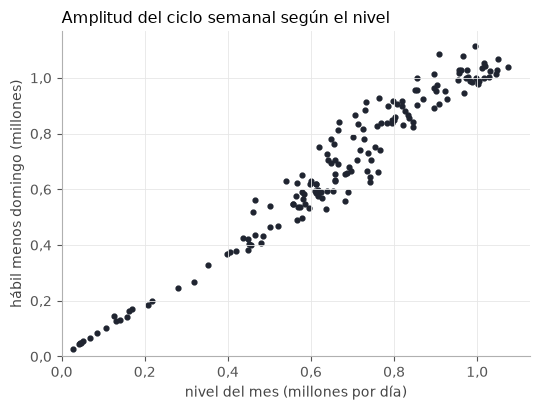

In [5]:
df = total.to_frame("pax").dropna()
df = df[~df.index.isin(no_habiles)]
df["mes"] = df.index.to_period("M")
df["tipo"] = np.where(df.index.day_of_week < 5, "habil", np.where(df.index.day_of_week == 6, "domingo", "sabado"))
por_mes = df.groupby(["mes", "tipo"])["pax"].mean().unstack()
por_mes["nivel"] = total.resample("MS").mean().to_period("M").reindex(por_mes.index)
por_mes["amplitud"] = por_mes["habil"] - por_mes["domingo"]
por_mes = por_mes.dropna()

fig, ax = plt.subplots(figsize=(5.5, 4.2))
ax.scatter(por_mes["nivel"], por_mes["amplitud"], s=12, color=TINTA)
ax.xaxis.set_major_formatter(en_millones)
ax.yaxis.set_major_formatter(en_millones)
ax.set_xlabel("nivel del mes (millones por día)")
ax.set_ylabel("hábil menos domingo (millones)")
ax.set_title("Amplitud del ciclo semanal según el nivel")
ax.set_xlim(left=0); ax.set_ylim(bottom=0)
fig.tight_layout()
print("Correlación entre nivel y amplitud:", num(por_mes["nivel"].corr(por_mes["amplitud"]), 2))
print("Domingo / hábil, mediana de los meses:", pct((por_mes["domingo"] / por_mes["habil"]).median()))

La amplitud crece con el nivel, casi en proporción: en los meses de 2020 con poca gente, la diferencia entre un hábil y un domingo también es chica. Eso es lo que describe un modelo multiplicativo. En escala logarítmica, una proporción fija ocupa siempre la misma altura:

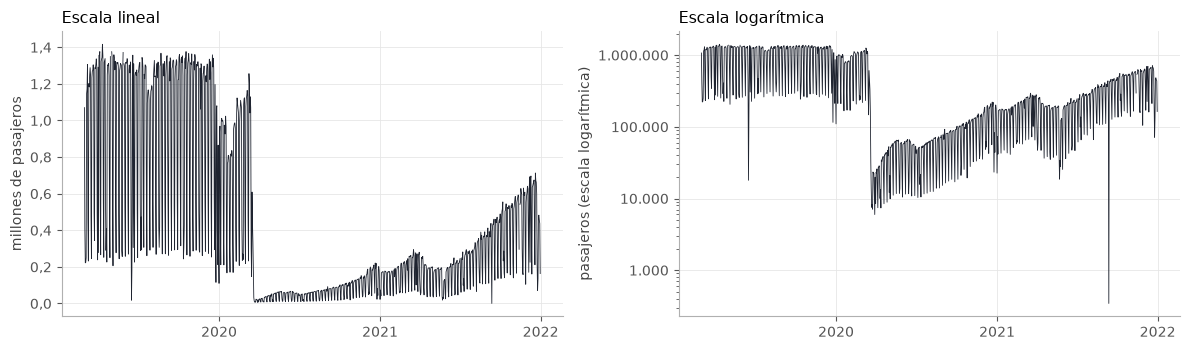

In [6]:
s = total.loc["2019-03":"2021-12"]
fig, axes = plt.subplots(1, 2, figsize=(12, 3.6))
axes[0].plot(s.index, s.values, color=TINTA, lw=0.6)
axes[0].yaxis.set_major_formatter(en_millones)
axes[0].set_ylabel("millones de pasajeros")
axes[0].set_title("Escala lineal")
axes[1].plot(s.index, s.values, color=TINTA, lw=0.6)
axes[1].set_yscale("log")
axes[1].yaxis.set_major_formatter(FuncFormatter(lambda v, _: num(v)))
axes[1].set_ylabel("pasajeros (escala logarítmica)")
axes[1].set_title("Escala logarítmica")
for ax in axes:
    ax.xaxis.set_major_locator(mdates.YearLocator())
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
fig.tight_layout()

En escala lineal, el ciclo semanal casi desaparece en 2020; en logarítmica, sigue ocupando un ancho parecido. Para modelar con piezas aditivas una serie así, conviene trabajar con el logaritmo.

## 3. `seasonal_decompose`

La descomposición clásica estima la tendencia con una media móvil centrada de un período, y el ciclo como el promedio de lo que queda para cada posición dentro del período (cada día de la semana, con `period=7`). No acepta valores faltantes, así que primero se interpolan los pocos días sin datos.

Días sin datos interpolados: ['13/08/2023', '09/05/2024', '30/10/2024']


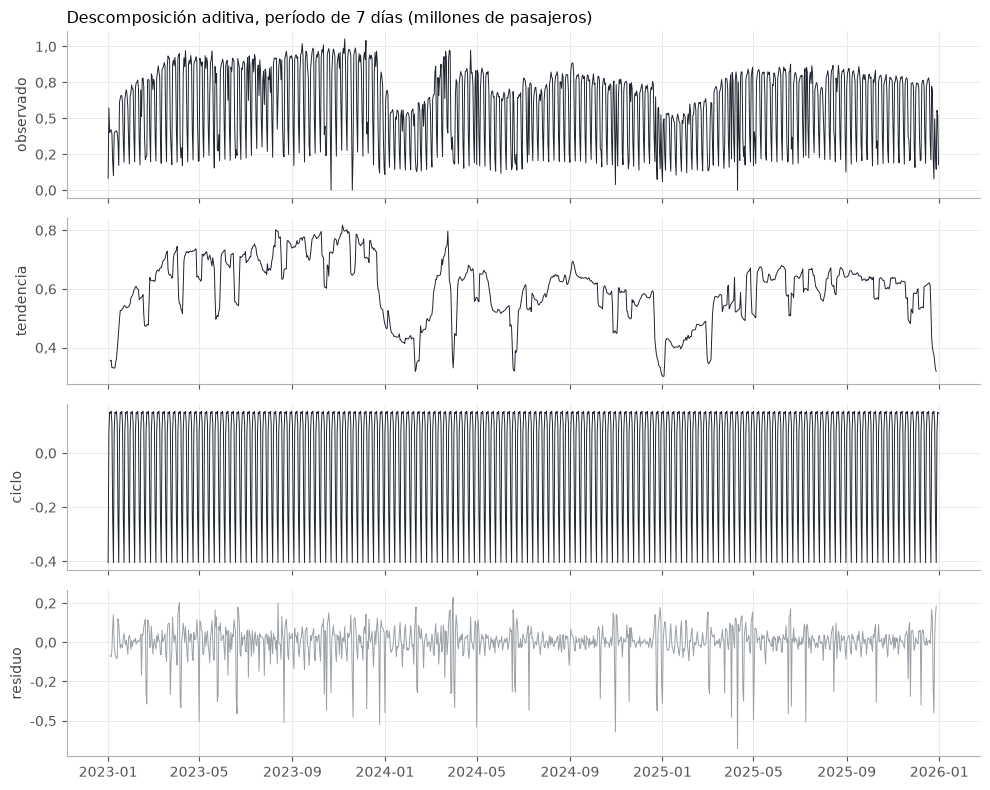

In [7]:
s = total.loc["2023":"2025"]
print("Días sin datos interpolados:", list(s[s.isna()].index.strftime("%d/%m/%Y")))
s = s.interpolate("time")

aditiva = seasonal_decompose(s, model="additive", period=7)
multiplicativa = seasonal_decompose(s, model="multiplicative", period=7)

def paneles(partes, titulo, formatos):
    fig, axes = plt.subplots(len(partes), 1, figsize=(10, 2 * len(partes)), sharex=True)
    for ax, (nombre, serie), fmt in zip(axes, partes.items(), formatos):
        ax.plot(serie.index, serie.values, color=TINTA if nombre != "residuo" else GRIS, lw=0.7)
        ax.set_ylabel(nombre)
        ax.yaxis.set_major_formatter(fmt)
    axes[0].set_title(titulo)
    fig.tight_layout()

paneles({"observado": s, "tendencia": aditiva.trend, "ciclo": aditiva.seasonal, "residuo": aditiva.resid},
        "Descomposición aditiva, período de 7 días (millones de pasajeros)", [en_millones] * 4)

In [8]:
ciclo = pd.DataFrame({
    "aditiva (pasajeros)": aditiva.seasonal.iloc[:7].values,
    "multiplicativa (factor)": multiplicativa.seasonal.iloc[:7].values,
}, index=[DIAS[d] for d in aditiva.seasonal.index[:7].day_of_week])
ciclo.loc[DIAS].round(2)

,aditiva (pasajeros),multiplicativa (factor)
lunes,78200.90,1.13
martes,150989.95,1.25
miércoles,147023.93,1.25
jueves,154288.33,1.26
viernes,109333.32,1.19
sábado,-234807.07,0.61
domingo,-405029.35,0.32


En la aditiva, el domingo resta una cantidad fija de pasajeros; en la multiplicativa, el domingo es una fracción del nivel. Con un solo período, la tendencia de 7 días se queda con todo lo demás: vacaciones, feriados y el ciclo anual.

## 4. `MSTL`: varios ciclos a la vez

`MSTL` (statsmodels) estima la tendencia y un ciclo por cada período con STL, un método de suavizado local. Con `robust=True`, los días muy raros pesan menos en la estimación. Se usa desde abril de 2022, cuando la serie ya había salido de las restricciones de 2020 y 2021 (ver el cuaderno 06).

In [9]:
s = total.loc["2022-04-01":"2026-08-31"]
falta = s.isna()
s = s.interpolate("time")
mstl = MSTL(s, periods=(7, 365), stl_kwargs={"robust": True}).fit()
comp = pd.DataFrame({
    "observado": s.where(~falta), "tendencia": mstl.trend,
    "ciclo semanal": mstl.seasonal["seasonal_7"], "ciclo anual": mstl.seasonal["seasonal_365"],
    "residuo": mstl.resid.where(~falta),
})
comp.head()

,observado,tendencia,ciclo semanal,ciclo anual,residuo
fecha,,,,,
2022-04-01,854793.0,665553.115319,173493.250270,22577.975950,-6831.341539
2022-04-02,363726.0,665578.882954,-291414.202408,1411.937620,-11850.618167
2022-04-03,200790.0,665604.651536,-477000.199337,11679.030952,506.516849
2022-04-04,816042.0,665630.421050,108860.213350,41047.821806,503.543794
2022-04-05,853048.0,665656.191482,179031.820394,922.561084,7437.427039


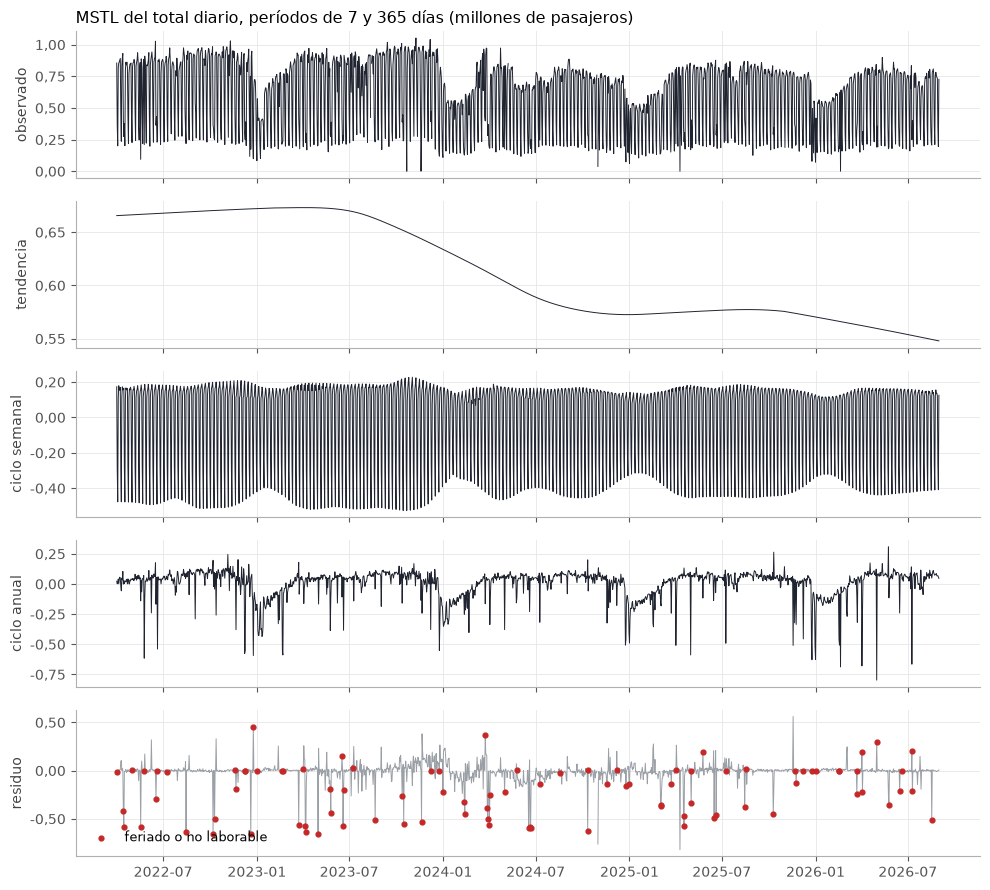

In [10]:
def dibujar_mstl(c, titulo):
    fig, axes = plt.subplots(5, 1, figsize=(10, 9), sharex=True)
    fer = c.index.isin(no_habiles)
    for ax, col in zip(axes, c.columns):
        ax.plot(c.index, c[col], color=GRIS if col == "residuo" else TINTA, lw=0.7 if len(c) > 400 else 1.1)
        if col == "residuo":
            ax.scatter(c.index[fer], c.loc[fer, col], s=12, color=ROJO, zorder=3, label="feriado o no laborable")
            ax.legend(loc="lower left")
        ax.set_ylabel(col)
        ax.yaxis.set_major_formatter(FuncFormatter(lambda v, _: num(v / 1e6, 2)))
    axes[0].set_title(titulo)
    fig.tight_layout()

dibujar_mstl(comp, "MSTL del total diario, períodos de 7 y 365 días (millones de pasajeros)")

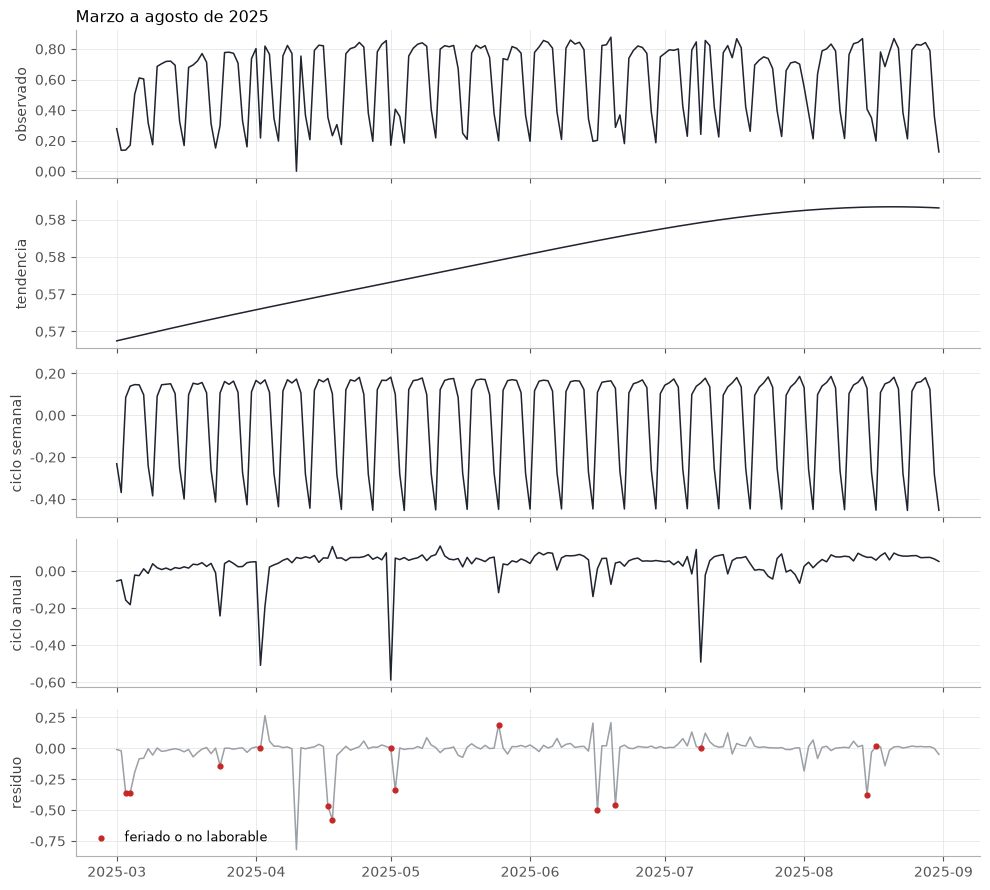

In [11]:
dibujar_mstl(comp.loc["2025-03":"2025-08"], "Marzo a agosto de 2025")

## 5. Los residuos como registro de eventos

El modelo no sabe qué es un feriado. Los de fecha fija (1 de enero, 1 de mayo, 25 de diciembre) se repiten cada 365 días y el ciclo anual los absorbe en parte: son los pozos angostos de ese panel. Los trasladables, los puentes y los paros no caen en la misma fecha cada año y quedan como residuos muy negativos. Los residuos más grandes son, en su mayoría, días con un hecho concreto detrás.

In [12]:
res = comp["residuo"].dropna()
top = res.abs().sort_values(ascending=False).head(40).index
print("De los 40 residuos más grandes,", int(top.isin(no_habiles).sum()), "caen en un feriado o día no laborable;")
print("esos días son el", pct(res.index.isin(no_habiles).mean(), 1), "del período.")

tabla = res.loc[top].rename("residuo").to_frame()
tabla["día"] = [DIAS[d] for d in tabla.index.day_of_week]
tabla = tabla.join(eventos[["tipo", "descripcion"]])
tabla["residuo"] = (tabla["residuo"] / 1e3).round(0)
tabla = tabla.rename(columns={"residuo": "residuo (miles)"})
pd.set_option("display.max_colwidth", 110)
tabla.head(15)

De los 40 residuos más grandes, 36 caen en un feriado o día no laborable;
esos días son el 5,7 % del período.


,residuo (miles),día,tipo,descripcion
fecha,,,,
2025-04-10,-821.0,jueves,paro_general,Paro general de la CGT: los metrodelegados adhirieron en forma total y no funcionaron las seis líneas ni e...
2024-10-31,-761.0,jueves,sin_explicar,Todas las líneas registran cerca del 5 % de lo normal en todos los horarios; la prensa anunciaba subte nor...
2022-12-20,-662.0,martes,feriado,Feriado nacional por la caravana de la selección campeona (Decreto 842/2022); las seis líneas y el Premetr...
2022-10-07,-660.0,viernes,puente,Día no laborable con fines turísticos fijado por el Decreto 789/2021.
2023-05-01,-660.0,lunes,feriado,Feriado nacional: Día del Trabajo (régimen de la Ley 27.399).
2023-04-07,-641.0,viernes,feriado,Feriado nacional: Viernes Santo (régimen de la Ley 27.399).
2022-08-15,-639.0,lunes,feriado,Feriado nacional: Paso a la Inmortalidad del General Don José de San Martín (régimen de la Ley 27.399).
2024-10-11,-625.0,viernes,puente,Día no laborable con fines turísticos fijado por el Decreto 106/2023.
2024-06-17,-595.0,lunes,feriado,Feriado nacional: Paso a la Inmortalidad del General Don Martín Miguel de Güemes (régimen de la Ley 27.399).


Con el logaritmo, la descomposición es multiplicativa y el residuo se lee como un porcentaje: $e^{r} - 1$ es cuánto se apartó ese día de lo que esperaban la tendencia y los ciclos.

In [13]:
mstl_log = MSTL(np.log(s), periods=(7, 365), stl_kwargs={"robust": True}).fit()
res_log = (np.exp(mstl_log.resid) - 1).where(~falta).dropna()
print("Residuo típico (mediana del valor absoluto):", pct(res_log.abs().median(), 1))
print("Días fuera de más o menos 30 %:", int((res_log.abs() > 0.3).sum()), "de", len(res_log))
peores = res_log.sort_values().head(8).rename("apartamiento").to_frame()
peores["apartamiento"] = peores["apartamiento"].map(pct)
peores.join(eventos[["tipo", "descripcion"]])

Residuo típico (mediana del valor absoluto): 2,1 %
Días fuera de más o menos 30 %: 114 de 1611


,apartamiento,tipo,descripcion
fecha,,,
2025-04-10,-100 %,paro_general,Paro general de la CGT: los metrodelegados adhirieron en forma total y no funcionaron las seis líneas ni e...
2023-11-19,-99 %,elecciones,"Segunda vuelta presidencial: subte, Premetro y Ecobici gratuitos, por eso los molinetes casi no registran ..."
2024-10-31,-95 %,sin_explicar,Todas las líneas registran cerca del 5 % de lo normal en todos los horarios; la prensa anunciaba subte nor...
2025-11-24,-83 %,feriado,Feriado nacional: Día de la Soberanía Nacional (régimen de la Ley 27.399).
2022-12-20,-80 %,feriado,Feriado nacional por la caravana de la selección campeona (Decreto 842/2022); las seis líneas y el Premetr...
2024-06-17,-79 %,feriado,Feriado nacional: Paso a la Inmortalidad del General Don Martín Miguel de Güemes (régimen de la Ley 27.399).
2024-06-21,-77 %,puente,Día no laborable con fines turísticos fijado por el Decreto 106/2023.
2023-05-01,-76 %,feriado,Feriado nacional: Día del Trabajo (régimen de la Ley 27.399).


## 6. Otra forma de estacionalidad: subte y Ecobici

El subte cuenta entradas por molinete; Ecobici, retiros de bicicletas. Para comparar formas y no volúmenes, cada curva es el porcentaje de los viajes del día que cae en cada hora (suma 100 %). Promedio de 2025, sin feriados.

Subte, días hábiles: pico de 6 a 10 h / pico de 16 a 20 h = 0,93
Ecobici, días hábiles: pico de 6 a 10 h / pico de 16 a 20 h = 0,50


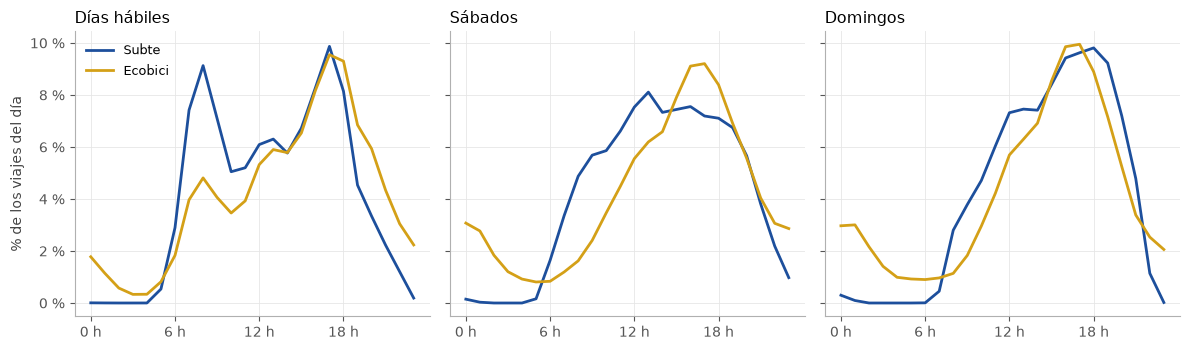

In [14]:
def tipo_de_dia(fechas):
    d = fechas.dt.day_of_week
    return np.select([d < 5, d == 5], ["días hábiles", "sábados"], "domingos")

q["hora"] = q["desde"].str[:2].astype(int)
qq = q[~q["fecha"].isin(no_habiles)]
sub = qq.groupby([tipo_de_dia(qq["fecha"]), "hora"])["pax"].sum().unstack()

eco = pd.read_csv(BASE + "ecobici_hora.csv", parse_dates=["fecha"])
eco = eco[(eco["fecha"].dt.year == 2025) & ~eco["fecha"].isin(no_habiles)]
ecob = eco.groupby([tipo_de_dia(eco["fecha"]), "hora"])["viajes"].sum().unstack()

fig, axes = plt.subplots(1, 3, figsize=(12, 3.6), sharey=True)
for ax, tipo in zip(axes, ["días hábiles", "sábados", "domingos"]):
    for tabla, nombre, color in ((sub, "Subte", LINEAS["C"]), (ecob, "Ecobici", ECOBICI)):
        fila = tabla.loc[tipo].reindex(range(24), fill_value=0)
        ax.plot(fila.index, fila / fila.sum(), color=color, lw=2, label=nombre)
        if tipo == "días hábiles":
            print(f"{nombre}, días hábiles: pico de 6 a 10 h / pico de 16 a 20 h =", num(fila.loc[6:9].max() / fila.loc[16:19].max(), 2))
    ax.set_title(tipo.capitalize())
    ax.set_xticks(range(0, 24, 6), [f"{h} h" for h in range(0, 24, 6)])
axes[0].yaxis.set_major_formatter(FuncFormatter(lambda v, _: pct(v)))
axes[0].set_ylabel("% de los viajes del día")
axes[0].legend()
fig.tight_layout()

Los días hábiles las dos series tienen un pico a la mañana y otro a la tarde, pero en Ecobici el de la mañana es mucho más bajo. Los fines de semana las dos se corren hacia la tarde, y Ecobici conserva más viajes de noche.

## Para seguir

1. Hacer la descomposición MSTL de `ecobici_diario.csv` desde 2022 (con logaritmo) y comparar el ciclo semanal con el del subte: ¿cuánto pesa el domingo en cada serie?
2. Comparar los factores multiplicativos del ciclo semanal de 2019 con los de 2025 usando `seasonal_decompose` en cada año. ¿Cambió el peso de los viernes?
3. Ordenar los días por residuo de MSTL y por el cociente del cuaderno 01. ¿Los dos métodos marcan los mismos días? ¿En qué casos difieren?